# Notebook 04 — Embudo de variantes: de 5 millones a la causa

**MVA Hackathon 2026 · Track 2** · rehecho el 15 oct 2026 (Ktalyna con Claude Code)

**Pregunta:** de todas las variantes del genoma del paciente, ¿cuál explica el MVA? ¿Y hay algo más que explique lo que el MVA no explica?

**Por qué se rehízo.** La versión anterior dibujaba un embudo de 19.099 variantes, pero el código solo miraba 6 genes, y gnomAD se consultaba solo para *BUB1B*, *CEP57* y *TRIP13*. Además:
- descartaba las homocigotas, que son lo primero que hay que buscar en una enfermedad recesiva;
- usaba la consecuencia del primer transcrito de SnpEff, no la del transcrito MANE (por eso el alelo 2 salió una vez como "intergénico");
- deducía que dos heterocigotas están en copias distintas, lo que no es cierto.

Este notebook aplica el mismo embudo a **todo el panel de 321 genes** y muestra cuántas variantes quedan en cada paso. Usa el código validado en A8 (`scripts/diagnostico_diferencial.py`) y agrega un segundo embudo con **modelo dominante** (`scripts/modelo_dominante.py`, tarea A10).

**Privacidad:** las tablas con variantes del paciente se guardan en `data/` (no se versiona). Aquí solo se muestran conteos y, para *BUB1B*, las dos variantes causantes.

In [1]:
import csv, gzip, importlib.util, sys
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
while not (RAIZ / "scripts").exists():
    RAIZ = RAIZ.parent
spec = importlib.util.spec_from_file_location("dd", RAIZ / "scripts" / "diagnostico_diferencial.py")
dd = importlib.util.module_from_spec(spec); spec.loader.exec_module(dd)
EMBUDO = RAIZ / "data" / "embudo"          # variantes del paciente: no se versiona
EMBUDO.mkdir(parents=True, exist_ok=True)
print("VCF:", dd.VCF.name, "| panel:", len(dd.leer_genes()), "genes")

VCF: WGS_EX2312012_HGWCNDSX7.vcf.gz | panel: 321 genes


## Paso 1 · Control de calidad

`PASS` es el sello del laboratorio (GATK VariantFiltration: QD < 2, MQ < 40, FS > 60…). Las que no lo tienen se revisaron aparte en el notebook 02b (A9): ninguna cambia el resultado.

In [2]:
total, pase, zig = 0, 0, Counter()
with gzip.open(dd.VCF, "rt", encoding="utf-8", errors="replace") as fh:
    for linea in fh:
        if linea[0] == "#":
            continue
        total += 1
        p = linea.split("\t", 10)
        if p[6] != "PASS":
            continue
        pase += 1
        gt = p[9].split(":")[0].replace("|", "/").split("/")
        alt = [a for a in gt if a not in ("0", ".")]
        if alt:
            zig["HOM" if len(alt) == len(gt) and len(set(alt)) == 1 else "HET"] += 1
print(f"Variantes en el VCF:  {total:,}")
print(f"PASS:                 {pase:,} ({pase/total:.1%})")
print(f"  heterocigotas:      {zig['HET']:,}")
print(f"  homocigotas:        {zig['HOM']:,}")

Variantes en el VCF:  5,012,204
PASS:                 4,740,790 (94.6%)
  heterocigotas:      2,913,813
  homocigotas:        1,826,977


## Pasos 2 a 5 · El embudo sobre los 321 genes

| Paso | Filtro | Por qué |
|---|---|---|
| 2 | Variante PASS dentro de un gen del panel (`config/genes_candidatos.txt`) | Genes de mitosis, cinetocoro, centrosoma, cohesina, reparación, ciclo celular y los seis genes de MVA con número en OMIM |
| 3 | AF < 1 % en gnomAD v4 (exomas y genomas) o sin dato | Una enfermedad tan rara no puede deberse a una variante frecuente. **Ojo:** la lista de gnomAD por gen omite casi todas las variantes intrónicas, que quedan como "sin dato" e inflan este paso; se eliminan en el paso 4, y las que cambian la proteína se consultan una por una en gnomAD |
| 4 | Efecto en la proteína en algún transcrito (pérdida de función, missense, *inframe*) | Las intrónicas o sinónimas no se evalúan con este método |
| 5 | Efecto en el transcrito **MANE Select** | El transcrito de referencia clínica; evita falsas alarmas de transcritos secundarios |
| 6 | Patrón recesivo: ≥ 1 homocigota o ≥ 2 heterocigotas en el mismo gen | El MVA es autosómico recesivo |

Las homocigotas **sí** se incluyen (en la versión anterior se descartaban).

In [3]:
dd.OUT = EMBUDO
sys.argv = ["diagnostico_diferencial.py"]
dd.main()

genes = list(csv.DictReader(open(EMBUDO / "diagnostico_diferencial_genes.tsv", encoding="utf-8"), delimiter="\t"))
varis = list(csv.DictReader(open(EMBUDO / "diagnostico_diferencial_variantes.tsv", encoding="utf-8"), delimiter="\t"))
suma = lambda col: sum(int(float(g[col])) for g in genes if g.get(col) not in ("", None))
mane = [v for v in varis if v["cuenta"] == "True"]
pasos = [
    ("2 · PASS en los 321 genes", suma("variantes_pass")),
    ("3 · raras o sin dato en gnomAD*", suma("raras_o_ausentes")),
    ("4 · efecto en algún transcrito", suma("alertas_cualquier_transcrito")),
    ("5 · efecto en el transcrito MANE", suma("raras_funcionales")),
]
for nombre, n in pasos:
    print(f"{nombre:36s} {n:>7,}")
print("   * casi todas intrónicas sin dato en la lista de gnomAD por gen; no pasan el paso 4")
print(f"   de ellas homocigotas:              {sum(v['zig'] == 'HOM' for v in mane):>7,}")
print(f"   en genes analizados:               {sum(g['analizado'] == 'True' for g in genes)} de {len(genes)}")
recesivos = [g["gen"] for g in genes if g.get("patron_recesivo") == "True"]
print(f"6 · genes con patrón recesivo:        {len(recesivos):>7}  -> {', '.join(recesivos)}")

321 genes a analizar


CENPR -> ITGB3BP


CENPJ -> CPAP


FANCP -> SLX4


FANCQ -> ERCC4


...

ANAPC8 -> CDC23


NO ANALIZADO IL40: no encontrado


320 de 321 genes resueltos; 1 sin analizar; leyendo el VCF...


24604 variantes del paciente en el panel; 23239 ausentes de gnomAD -> VEP
19 variantes raras con efecto funcional en algún transcrito; 14 lo mantienen en MANE
Guardado en results/


2 · PASS en los 321 genes             24,604
3 · raras o sin dato en gnomAD*       23,242
4 · efecto en algún transcrito            19
5 · efecto en el transcrito MANE          14
   * casi todas intrónicas sin dato en la lista de gnomAD por gen; no pasan el paso 4
   de ellas homocigotas:                    0
   en genes analizados:               320 de 321
6 · genes con patrón recesivo:              1  -> BUB1B


### Resultado por gen (solo conteos)

Genes con al menos una variante rara que cambia la proteína en el transcrito MANE. No se muestran posiciones fuera de *BUB1B*.

In [4]:
tabla = sorted((g for g in genes if g.get("raras_funcionales") not in ("", None, "0")),
               key=lambda g: (g["patron_recesivo"] != "True", -int(g["lof"] or 0), g["gen"]))
print(f"{'gen':10s} {'MANE':>5s} {'LOF':>4s} {'hom':>4s} {'het':>4s}  patrón recesivo")
for g in tabla:
    print(f"{g['gen']:10s} {g['raras_funcionales']:>5s} {g['lof']:>4s} {g['hom_funcionales']:>4s} {g['het_funcionales']:>4s}  "
          f"{'SÍ' if g['patron_recesivo'] == 'True' else '-'}")

gen         MANE  LOF  hom  het  patrón recesivo
BUB1B          2    1    0    2  SÍ
ATM            1    0    0    1  -
CENPO          1    0    0    1  -
KDM6B          1    0    0    1  -
MAD1L1         1    0    0    1  -
MINAR1         1    0    0    1  -
RAD54L         1    0    0    1  -
SASS6          1    0    0    1  -
SMC4           1    0    0    1  -
SUZ12          1    0    0    1  -
SYNE2          1    0    0    1  -
TUBB8          1    0    0    1  -
TUBGCP6        1    0    0    1  -


In [5]:
print("Variantes de BUB1B que pasan el embudo:")
for v in (v for v in mane if v["gen"] == "BUB1B"):
    af = f"{float(v['af']):.2e}" if v["af"] not in ("", "None") else "ausente"
    print(f"  {v['chrom']}:{v['pos']} {v['ref']}>{v['alt']}  {v['zig']}  {v['consecuencia_mane']:18s} "
          f"{v['hgvsp'].split(':')[-1]:14s} AF gnomAD {af}")

Variantes de BUB1B que pasan el embudo:
  15:40209701 T>G  HET  stop_gained        p.Leu737Ter    AF gnomAD 7.87e-05
  15:40220612 T>G  HET  missense_variant   p.Asn1002Lys   AF gnomAD 6.84e-07


## Paso 6 · ¿Están en copias distintas?

Que las dos variantes sean heterocigotas **no** prueba que estén en copias distintas (*trans*): también podrían estar en la misma (*cis*), y entonces el paciente tendría una copia sana. Con este dataset la fase **no se puede resolver**: no hay muestras de los padres, el VCF no trae etiquetas de fase y la única heterocigota intermedia está a 6,8 y 4,1 kb, demasiado lejos para lecturas cortas. El argumento a favor de *trans* es indirecto: en *cis* no se esperaría la enfermedad. Clasificación ACMG y detalle: `docs/secciones/01_variante_causante.md`.

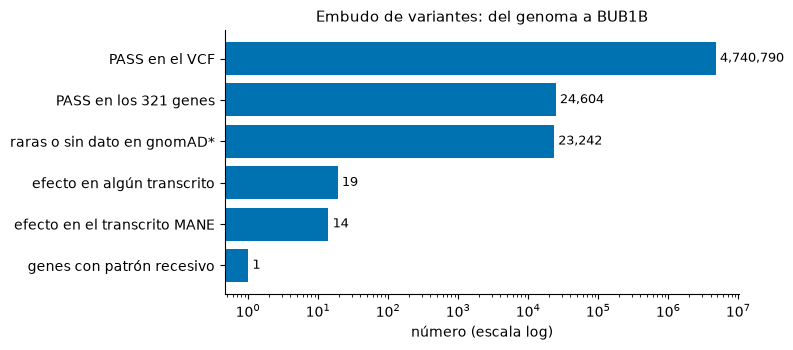

In [6]:
etiquetas = ["PASS en el VCF"] + [p[0].split(" · ")[1] for p in pasos] + ["genes con patrón recesivo"]
valores = [pase] + [p[1] for p in pasos] + [len(recesivos)]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(etiquetas[::-1], valores[::-1], color="#0072B2")
for i, v in enumerate(valores[::-1]):
    ax.text(v * 1.15, i, f"{v:,}", va="center", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("número (escala log)")
ax.set_title("Embudo de variantes: del genoma a BUB1B", fontsize=11)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(RAIZ / "results" / "figura_embudo_variantes.png", dpi=150, bbox_inches="tight")
plt.show()

## Paso 7 · Modelo dominante: ¿un segundo diagnóstico? (A10)

El MVA explica el rabdomiosarcoma, la restricción del crecimiento y la atrofia, pero **no la nefrocalcinosis**. Y algunos síndromes dominantes (Costello, Noonan, Li-Fraumeni, DICER1) también predisponen al rabdomiosarcoma. Alrededor de 5–7 % de los pacientes con diagnóstico genético tienen **dos diagnósticos a la vez**.

`scripts/modelo_dominante.py` toma 92 genes de 8 paneles de PanelApp (nefrocalcinosis, tubulopatías, calcio y paratiroides, CASR, rabdomiosarcoma familiar, tumores sólidos infantiles, sarcomas, talla baja). Solo entran genes verdes en los que una sola copia alterada causa enfermedad. Después aplica el embudo dominante:
- heterocigota con efecto en el transcrito MANE;
- **AF ≤ 1×10⁻⁵** en gnomAD v4 o ausente, porque una enfermedad dominante grave de la infancia no puede ser frecuente;
- GQ ≥ 20 y DP ≥ 10.

El script se corre aparte (`python scripts/modelo_dominante.py`); esta celda solo lee su resultado.

In [7]:
DOM = RAIZ / "data" / "dominante"
gd = list(csv.DictReader(open(DOM / "diagnostico_diferencial_genes.tsv", encoding="utf-8"), delimiter="\t"))
vd = list(csv.DictReader(open(DOM / "diagnostico_diferencial_variantes.tsv", encoding="utf-8"), delimiter="\t"))
cand = list(csv.DictReader(open(DOM / "candidatos_dominantes.tsv", encoding="utf-8"), delimiter="\t"))
sd = lambda col: sum(int(float(g[col])) for g in gd if g.get(col) not in ("", None))
het = [v for v in vd if v["zig"] == "HET" and v["cuenta"] == "True"]
print(f"genes del modelo dominante:              {len(gd)}")
print(f"PASS en esos genes:                      {sd('variantes_pass'):,}")
print(f"raras (AF < 1 %) o ausentes:             {sd('raras_o_ausentes'):,}")
print(f"efecto en el transcrito MANE:            {sd('raras_funcionales')}")
print(f"heterocigotas con efecto en MANE:        {len(het)}")
print(f"AF <= 1e-5 o ausentes, buena calidad:    {len(cand)}")
for c in cand:
    print(f"  -> {c['gen']}: {c['consecuencia_mane']}, ClinVar: {c['clinvar'] or 'sin registro'}, "
          f"REVEL {c['revel'] or '-'}, LOEUF {c['loeuf'] or '-'}, herencia: {c['herencia'][:40]}")

genes del modelo dominante:              92
PASS en esos genes:                      11,808
raras (AF < 1 %) o ausentes:             11,447
efecto en el transcrito MANE:            2
heterocigotas con efecto en MANE:        2
AF <= 1e-5 o ausentes, buena calidad:    1
  -> LZTR1: stop_gained, ClinVar: Likely pathogenic; Pathogenic, REVEL -, LOEUF 2.7248174083640535, herencia: BOTH monoallelic and biallelic, autosoma


## Conclusión

- **Causa principal (modelo recesivo):** de 24.604 variantes PASS en los 321 genes quedan 19 raras con efecto en alguna proteína y 14 en el transcrito MANE, todas heterocigotas. Solo *BUB1B* tiene dos (p.Leu737Ter + p.Asn1002Lys): es el único gen con patrón recesivo, y no hay ninguna variante rara funcional en homocigosis.
- **Modelo dominante (92 genes, 8 paneles de PanelApp):** una sola candidata, una truncante heterocigota en *LZTR1* (AF 1,4×10⁻⁶, germinal). No explica el MVA ni la nefrocalcinosis y no causa Noonan; es un **hallazgo secundario**: predisposición a la schwannomatosis por *LZTR1*. Abre una hipótesis comprobable en el tumor: si perdió la otra copia, la vía RAS estaría activa.
- **Nefrocalcinosis:** ningún gen renal la explica (92 genes dominantes y 48 recesivos); lo más probable es la prematuridad.

Detalle e interpretación: `docs/secciones/01_variante_causante.md`, secciones 5 y 5c.